## 1. Imports & Setup

Підключаємо бібліотеки для роботи з підготовленими annotations, завантаження зображень і навчання RetinaNet на GPU.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

from pathlib import Path
from zipfile import ZipFile

HW_ROOT = Path("/content/drive/MyDrive/AI_HW2")
DATA_ROOT = Path("/content/visdrone")
PREPROCESSED_ROOT = HW_ROOT / "preprocessed"

zip_path = HW_ROOT / "multiple-object-video-detection-hw-2-ucu-ai-2026.zip"
ready_file = DATA_ROOT / ".train_extracted"

assert zip_path.is_file(), "Dataset ZIP not found"

if not ready_file.exists():
    with ZipFile(zip_path) as z:
        train_files = [
            name for name in z.namelist()
            if name.startswith("train/") and not name.endswith("/")
        ]

        print(f"Extracting {len(train_files)} training files...")
        z.extractall(DATA_ROOT, members=train_files)

    ready_file.touch()
    print("Extraction completed")
else:
    print("Training data already extracted")

assert (DATA_ROOT / "train/images").is_dir()
assert (PREPROCESSED_ROOT / "train.json").is_file()
assert (PREPROCESSED_ROOT / "folds.json").is_file()

print("Dataset ready:", DATA_ROOT)


Extracting 66494 training files...
Extraction completed
Dataset ready: /content/visdrone


In [ ]:
import json

PREPROCESSED_ROOT = HW_ROOT / "preprocessed"

with open(PREPROCESSED_ROOT / "train.json") as f:
    train_data = json.load(f)

with open(PREPROCESSED_ROOT / "folds.json") as f:
    fold_assignments = json.load(f)

assert len(train_data) == 24201
assert len(fold_assignments) == len(train_data)
assert set(fold_assignments) == {
    str(r["file_name"]) for r in train_data
}

print("Records:", len(train_data))
print("Folds:", set(fold_assignments.values()))

Records: 24201
Folds: {0, 1, 2}


In [ ]:

import json
from pathlib import Path

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

DATA_ROOT = Path("/content/visdrone")

assert (DATA_ROOT / "train/images").is_dir(), (
    "Training images not found"
)

print("Device:", DEVICE)
print("Data root:", DATA_ROOT)


Device: cuda
Data root: /content/visdrone


In [ ]:
%pip install -q pycocotools

## 2. Load Preprocessed Annotations

Використовуємо готові train та validation annotations із preprocessing notebook. Bounding boxes уже конвертовано у формат XYXY, а ignored regions збережено окремо.

In [ ]:
import random
import re
from collections import defaultdict
import numpy as np

SEED = 42
FOLD = 1

N_SPLITS = 3
TRAIN_FRAME_STEP = 6
VAL_FRAME_STEP = 2

EPOCHS = 6
BATCH_SIZE = 2
LR = 1e-4

assert FOLD in range(N_SPLITS)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


def sequence_name(rec):
    return Path(
        str(rec["file_name"]).replace("\\", "/")
    ).parent.name


def frame_sort_key(rec):
    name = Path(rec["file_name"]).stem
    match = re.search(r"(\d+)$", name)

    return (
        int(match.group(1)) if match else float("inf"),
        name
    )


def sample_by_sequence(records, step):
    grouped = defaultdict(list)

    for rec in records:
        grouped[sequence_name(rec)].append(rec)

    selected = []

    for sequence in sorted(grouped):
        frames = sorted(
            grouped[sequence],
            key=frame_sort_key
        )
        selected.extend(frames[::step])

    return selected


full_fold_train = [
    rec for rec in train_data
    if fold_assignments[rec["file_name"]] != FOLD
]

full_fold_val = [
    rec for rec in train_data
    if fold_assignments[rec["file_name"]] == FOLD
]

fold_train_data = sample_by_sequence(
    full_fold_train, TRAIN_FRAME_STEP
)

fold_val_data = sample_by_sequence(
    full_fold_val, VAL_FRAME_STEP
)

train_sequences = set(map(sequence_name, fold_train_data))
val_sequences = set(map(sequence_name, fold_val_data))

assert train_sequences.isdisjoint(val_sequences)
assert fold_train_data and fold_val_data

print(f"Fold {FOLD}")
print(f"Train: {len(full_fold_train)} -> {len(fold_train_data)}")
print(f"Validation: {len(full_fold_val)} -> {len(fold_val_data)}")
print("Train sequences:", len(train_sequences))
print("Val sequences:", len(val_sequences))


Fold 1
Train: 16119 -> 2706
Validation: 8082 -> 4046
Train sequences: 37
Val sequences: 19


## 3. Dataset & DataLoader

Створюємо PyTorch Dataset на основі попередньо підготовлених annotations. Для train використовуємо RandomHorizontalFlip, а для validation — лише перетворення зображень у тензори.

DataLoader формує batches із зображень та відповідних bounding boxes для навчання RetinaNet.

In [ ]:

import numpy as np
from PIL import Image
from torchvision import tv_tensors
from torchvision.transforms import v2 as T

class DetectionDataset(Dataset):
    def __init__(self, records, split, train=False):
        self.records = records
        self.split = split
        self.transforms = T.Compose(
            ([T.RandomHorizontalFlip(p=0.5)] if train else []) +
            [T.ToDtype(torch.float32, scale=True), T.ToPureTensor()]
        )

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        path = DATA_ROOT / self.split / rec["file_name"]

        with Image.open(path) as img:
            image = np.array(img.convert("RGB"), copy=True)

        h, w = image.shape[:2]
        image = tv_tensors.Image(torch.from_numpy(image).permute(2, 0, 1))

        target = {
            "boxes": tv_tensors.BoundingBoxes(
                torch.tensor(rec["boxes"], dtype=torch.float32).reshape(-1, 4),
                format="XYXY", canvas_size=(h, w)
            ),
            "labels": torch.tensor(rec["labels"], dtype=torch.int64),
            "ignored_boxes": tv_tensors.BoundingBoxes(
                torch.tensor(rec["ignored_boxes"], dtype=torch.float32).reshape(-1, 4),
                format="XYXY", canvas_size=(h, w)
            )
        }

        return self.transforms(image, target)

def collate_fn(batch):
    return tuple(zip(*batch))


train_dataset = DetectionDataset(
    fold_train_data,
    split="train",
    train=True
)

val_dataset = DetectionDataset(
    fold_val_data,
    split="train",
    train=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))


Training images: 2706
Validation images: 4046


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

## 4. RetinaNet Baseline

Використовуємо pretrained RetinaNet з ResNet-50 backbone та Feature Pyramid Network (FPN). Модель ініціалізована вагами, навченими на COCO, а classification head адаптуємо до 8 класів нашого датасету.

На baseline етапі залишаємо стандартні anchors і loss functions без модифікацій, щоб надалі оцінити вплив hyperparameter tuning.

In [ ]:

from torchvision.models.detection import (
    retinanet_resnet50_fpn,
    RetinaNet_ResNet50_FPN_Weights
)
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

NUM_CLASSES = 9

model = retinanet_resnet50_fpn(
    weights=RetinaNet_ResNet50_FPN_Weights.DEFAULT
)

num_anchors = model.anchor_generator.num_anchors_per_location()[0]

model.head.classification_head = RetinaNetClassificationHead(
    model.backbone.out_channels,
    num_anchors,
    NUM_CLASSES
)

model = model.to(DEVICE)


Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:01<00:00, 117MB/s]


## 5. Baseline Training

Навчаємо pretrained RetinaNet із початковими гіперпараметрами, стандартними anchors та Focal Loss.

Перед навчанням враховуємо ignored regions: негативні anchors, центри яких потрапляють у такі області, виключаємо з classification loss. Позитивні anchors, зіставлені з розміченими об'єктами, залишаємо без змін.

In [ ]:

from torchvision.models.detection.transform import resize_boxes

original_resize = model.transform.resize

def resize_with_ignore(image, target):
    old_size = image.shape[-2:]
    image, target = original_resize(image, target)

    if target is not None and "ignored_boxes" in target:
        target["ignored_boxes"] = resize_boxes(
            target["ignored_boxes"], old_size, image.shape[-2:]
        )

    return image, target

model.transform.resize = resize_with_ignore


In [ ]:

from types import MethodType
from torchvision.ops import box_iou
from torchvision.models.detection import _utils as det_utils

def compute_loss_with_ignore(self, targets, head_outputs, anchors):
    matched_idxs = []

    for anchor, target in zip(anchors, targets):
        boxes = target["boxes"]

        if len(boxes):
            matches = self.proposal_matcher(box_iou(boxes, anchor))
        else:
            matches = torch.full(
                (len(anchor),), -1, dtype=torch.long, device=anchor.device
            )

        ignored = target.get("ignored_boxes")
        if ignored is not None and len(ignored):
            centers = (anchor[:, :2] + anchor[:, 2:]) / 2
            ignore_mask = torch.zeros(len(anchor), dtype=torch.bool, device=anchor.device)

            for box in ignored.unique(dim=0):
                ignore_mask |= (
                    (centers[:, 0] >= box[0]) &
                    (centers[:, 0] <= box[2]) &
                    (centers[:, 1] >= box[1]) &
                    (centers[:, 1] <= box[3])
                )

            matches[(matches < 0) & ignore_mask] = det_utils.Matcher.BETWEEN_THRESHOLDS

        matched_idxs.append(matches)

    return self.head.compute_loss(targets, head_outputs, anchors, matched_idxs)

model.compute_loss = MethodType(compute_loss_with_ignore, model)


In [ ]:

from tqdm.auto import tqdm

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=DEVICE.type == "cuda"
)

OUTPUT_DIR = HW_ROOT / "retinanet" / f"fold_{FOLD}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = OUTPUT_DIR / "fold_latest.pth"

print("Saving to:", OUTPUT_DIR)


Saving to: /content/drive/MyDrive/AI_HW2/retinanet/fold_1


In [ ]:

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for images, targets in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):
        images = [img.to(DEVICE) for img in images]

        targets = [
            {k: v.to(DEVICE) for k, v in t.items()}
            for t in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            "cuda",
            enabled=DEVICE.type == "cuda"
        ):
            losses = model(images, targets)
            loss = sum(losses.values())

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch+1}"
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(images)

    epoch_loss = total_loss / len(train_dataset)
    train_losses.append(epoch_loss)

    payload = {
        "fold": FOLD,
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "train_losses": train_losses,
        "train_frame_step": TRAIN_FRAME_STEP,
        "val_frame_step": VAL_FRAME_STEP,
        "epochs": EPOCHS,
        "lr": LR,
    }

    temp_path = checkpoint_path.with_suffix(".tmp")
    torch.save(payload, temp_path)
    temp_path.replace(checkpoint_path)

    print(
        f"Epoch {epoch+1}/{EPOCHS}: "
        f"Loss = {epoch_loss:.4f}",
        flush=True
    )

print("Training finished")


Epoch 1/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 1/6: Loss = 0.6677


Epoch 2/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 2/6: Loss = 0.5374


Epoch 3/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 3/6: Loss = 0.4471


... (2 outputs left out)

Epoch 5/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 5/6: Loss = 0.3929


Epoch 6/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 6/6: Loss = 0.3886
Training finished


## 6. Baseline Evaluation

We evaluate the trained RetinaNet baseline on the held-out
validation set.

The model is evaluated using detection metrics, including
mAP, AP50, AP_small, AP_medium, and AP_large.

We also measure inference speed to compare the efficiency
of different detector architectures.

In [ ]:
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["fold"] == FOLD

model.load_state_dict(checkpoint["model"])
model.to(DEVICE)
model.eval()

print("Loaded fold:", checkpoint["fold"])
print("Loaded epoch:", checkpoint["epoch"])
print("Training losses:", checkpoint["train_losses"])

Loaded fold: 1
Loaded epoch: 6
Training losses: [0.6676715705364789, 0.5373836865336121, 0.4470815332902421, 0.4100399941800703, 0.39293625673275034, 0.3885500928592171]


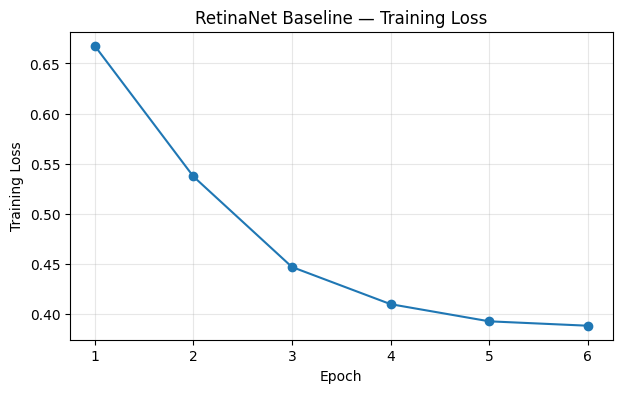

In [ ]:

import matplotlib.pyplot as plt

train_losses = checkpoint["train_losses"]

plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("RetinaNet Baseline — Training Loss")
plt.xticks(range(1, len(train_losses) + 1))
plt.grid(alpha=0.3)
plt.show()


In [ ]:

import time
import json
import numpy as np

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm


CLASS_NAMES = {
    1: "person",
    2: "bicycle",
    3: "car",
    4: "van",
    5: "truck",
    6: "tricycle",
    7: "bus",
    8: "motor"
}


def xyxy_to_xywh(box):
    x1, y1, x2, y2 = [float(v) for v in box]
    return [
        x1, y1,
        max(0.0, x2 - x1),
        max(0.0, y2 - y1)
    ]


def build_coco_gt(records):
    images = []
    annotations = []
    annotation_id = 1

    for rec in records:
        image_id = int(rec["image_id"])

        images.append({
            "id": image_id,
            "file_name": rec["file_name"]
        })

        for box, label in zip(rec["boxes"], rec["labels"]):
            bbox = xyxy_to_xywh(box)

            if bbox[2] <= 0 or bbox[3] <= 0:
                continue

            annotations.append({
                "id": annotation_id,
                "image_id": image_id,
                "category_id": int(label),
                "bbox": bbox,
                "area": bbox[2] * bbox[3],
                "iscrowd": 0
            })
            annotation_id += 1

        for box in rec["ignored_boxes"]:
            bbox = xyxy_to_xywh(box)

            if bbox[2] <= 0 or bbox[3] <= 0:
                continue

            for label in CLASS_NAMES:
                annotations.append({
                    "id": annotation_id,
                    "image_id": image_id,
                    "category_id": label,
                    "bbox": bbox,
                    "area": bbox[2] * bbox[3],
                    "iscrowd": 1
                })
                annotation_id += 1

    coco = COCO()
    coco.dataset = {
        "images": images,
        "annotations": annotations,
        "categories": [
            {"id": i, "name": name}
            for i, name in CLASS_NAMES.items()
        ],
        "info": {},
        "licenses": []
    }
    coco.createIndex()

    return coco


In [ ]:

def evaluate_retinanet(model, data_loader, records):
    model.eval()

    predictions = []
    inference_times = []

    assert len(records) == len(data_loader.dataset)

    record_index = 0

    with torch.inference_mode():
        for images, _ in tqdm(data_loader, desc="Validation"):
            images_gpu = [
                image.to(DEVICE, non_blocking=True)
                for image in images
            ]

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()
            outputs = model(images_gpu)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            elapsed = time.perf_counter() - start
            inference_times.append(elapsed / len(images))

            for output in outputs:
                rec = records[record_index]
                image_id = int(rec["image_id"])
                record_index += 1

                boxes = output["boxes"].cpu().tolist()
                labels = output["labels"].cpu().tolist()
                scores = output["scores"].cpu().tolist()

                for box, label, score in zip(boxes, labels, scores):
                    if int(label) not in CLASS_NAMES:
                        continue

                    bbox = xyxy_to_xywh(box)

                    if bbox[2] <= 0 or bbox[3] <= 0:
                        continue

                    predictions.append({
                        "image_id": image_id,
                        "category_id": int(label),
                        "bbox": bbox,
                        "score": float(score)
                    })

    assert record_index == len(records)

    coco_gt = build_coco_gt(records)

    if predictions:
        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(coco_gt, coco_dt, iouType="bbox")
        evaluator.params.imgIds = [
            int(r["image_id"]) for r in records
        ]
        evaluator.params.catIds = list(CLASS_NAMES)
        evaluator.params.maxDets = [1, 10, 100]

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

        stats = [float(v) for v in evaluator.stats]
    else:
        stats = [0.0] * 12

    mean_time = float(np.mean(inference_times))

    metrics = {
        "mAP": stats[0],
        "AP50": stats[1],
        "AP75": stats[2],
        "AP_small": stats[3],
        "AP_medium": stats[4],
        "AP_large": stats[5],
        "inference_ms_per_image": mean_time * 1000,
        "FPS_equivalent_batch1": (
            1.0 / mean_time if mean_time > 0 else 0.0
        ),
        "images_evaluated": len(records),
        "num_predictions": len(predictions)
    }

    return metrics, predictions


fold_metrics, fold_predictions = evaluate_retinanet(
    model,
    val_loader,
    fold_val_data
)

(OUTPUT_DIR / "metrics_quick.json").write_text(
    json.dumps(fold_metrics, indent=2)
)

(OUTPUT_DIR / "predictions_quick.json").write_text(
    json.dumps(fold_predictions)
)

(OUTPUT_DIR / "config.json").write_text(
    json.dumps({
        "fold": FOLD,
        "epochs": EPOCHS,
        "train_frame_step": TRAIN_FRAME_STEP,
        "val_frame_step": VAL_FRAME_STEP,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "seed": SEED,
        "validation_images": len(fold_val_data),
        "evaluation_note": (
            "COCO-style evaluation with category-specific "
            "crowd annotations for ignored regions"
        )
    }, indent=2)
)

print("Fold:", FOLD)
print(json.dumps(fold_metrics, indent=2))
print("Results saved to:", OUTPUT_DIR)


Validation:   0%|          | 0/4046 [00:00<?, ?it/s]

creating index...
index created!
Loading and preparing results...
DONE (t=1.70s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=372.15s).
Accumulating evaluation results...
DONE (t=6.51s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.128
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.249
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.116
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.022
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.132
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.276
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.076
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.185
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.229
 Average Recall     (AR) @[ IoU=0

In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

HW_ROOT = Path("/content/drive/MyDrive/AI_HW2")
fold_dir = HW_ROOT / "retinanet" / "fold_1"

required = [
    "fold_latest.pth",
    "metrics_quick.json",
    "predictions_quick.json",
    "config.json",
]

for name in required:
    assert (fold_dir / name).is_file(), f"Missing: {name}"

zip_path = HW_ROOT / "retinanet_fold_1_results.zip"

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for file in fold_dir.iterdir():
        if file.is_file():
            archive.write(file, arcname=f"fold_1/{file.name}")

print("Archive saved:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024**2, 1), "MB")


Archive saved: /content/drive/MyDrive/AI_HW2/retinanet_fold_1_results.zip
Size: 378.9 MB


---

# RetinaNet — Fold 1: Experiment 1 & Experiment 2

- **Experiment 1:** learning rate `5e-5`, default focal alpha `0.25`.
- **Experiment 2:** learning rate `1e-4`, modified focal alpha `0.5`.


In [ ]:
from pathlib import Path
import torch

assert FOLD == 1, f"Wrong fold: {FOLD}"
assert TRAIN_FRAME_STEP == 6 and VAL_FRAME_STEP == 2
assert EPOCHS == 6 and BATCH_SIZE == 2
assert DEVICE.type == 'cuda', 'Select Colab T4 GPU before training'
assert len(fold_val_data) == 4046, f"Fold 1 validation count changed: {len(fold_val_data)}"
assert len(train_dataset) == len(fold_train_data)
assert len(val_dataset) == len(fold_val_data)
assert not (set(map(sequence_name, fold_train_data)) & set(map(sequence_name, fold_val_data)))

output_root = HW_ROOT / 'retinanet_tuning'
output_root.mkdir(parents=True, exist_ok=True)
testfile = output_root / '.write_test_fold1'
testfile.write_text('OK')
assert testfile.read_text() == 'OK'
testfile.unlink()
print('Fold 1:',len(fold_train_data),'training images,',len(fold_val_data),'validation images')
print('Google Drive is writable:', output_root)
print('GPU:', torch.cuda.get_device_name(0))

Fold 1: 2706 training images, 4046 validation images
Google Drive is writable: /content/drive/MyDrive/AI_HW2/retinanet_tuning
GPU: Tesla T4


### Safety check — archive the previous incomplete Experiment 1 (once)

In [ ]:
import shutil

legacy_dir = HW_ROOT / 'retinanet_tuning' / 'lr_5e-5' / 'fold_1'
legacy_ckpt = legacy_dir / 'fold_latest.pth'
backup_parent = HW_ROOT / 'retinanet_tuning' / 'old_fold1_backup'

if legacy_ckpt.is_file():
    previous_ckpt = torch.load(legacy_ckpt, map_location='cpu', weights_only=True)
    if 'focal_alpha' not in previous_ckpt:
        backup_parent.mkdir(parents=True, exist_ok=True)
        backup_dir = backup_parent / 'lr_5e-5_previous_run'
        if backup_dir.exists():
            raise FileExistsError(
                f'Backup already exists: {backup_dir}. Check Drive before retrying.'
            )
        del previous_ckpt
        shutil.move(str(legacy_dir), str(backup_dir))
        print('Previous 6-epoch run archived:', backup_dir)
        print('New Experiment 1 will start at epoch 0.')
    else:
        print('Existing NEW experiment checkpoint found: resume is enabled.')
        del previous_ckpt
else:
    print('No legacy Experiment 1 checkpoint: fresh start.')


Previous 6-epoch run archived: /content/drive/MyDrive/AI_HW2/retinanet_tuning/old_fold1_backup/lr_5e-5_previous_run
New Experiment 1 will start at epoch 0.


## Shared model and ignored-region handling

The original baseline implements two modifications: resizing ignored boxes and excluding unmatched negative anchors whose centers lie inside ignored regions. **Both experiments keep these identical.** For Experiment 2 only classification focal-loss `alpha` changes.

In [ ]:
from types import MethodType
from torchvision.models.detection import (
    retinanet_resnet50_fpn,
    RetinaNet_ResNet50_FPN_Weights,
    _utils as det_utils,
)
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.models.detection.transform import resize_boxes
from torchvision.ops import box_iou, sigmoid_focal_loss
from tqdm.auto import tqdm

NUM_CLASSES = 9

def create_retinanet(focal_alpha=0.25):
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    model = retinanet_resnet50_fpn(
        weights=RetinaNet_ResNet50_FPN_Weights.DEFAULT
    )
    n_anchors = model.anchor_generator.num_anchors_per_location()[0]
    model.head.classification_head = RetinaNetClassificationHead(
        model.backbone.out_channels, n_anchors, NUM_CLASSES
    )

    if focal_alpha != 0.25:
        def focal_loss_with_alpha(self, targets, head_outputs, matched_idxs):
            per_image_losses = []
            for target, logits, matches in zip(
                targets, head_outputs['cls_logits'], matched_idxs
            ):
                fg = matches >= 0
                cls_targets = torch.zeros_like(logits)
                if fg.any():
                    cls_targets[fg, target['labels'][matches[fg]]] = 1.0
                valid = matches != det_utils.Matcher.BETWEEN_THRESHOLDS
                classification_loss = sigmoid_focal_loss(
                    logits[valid], cls_targets[valid],
                    alpha=focal_alpha, gamma=2.0, reduction='sum'
                )
                per_image_losses.append(
                    classification_loss / max(1, int(fg.sum().item()))
                )
            return sum(per_image_losses) / len(per_image_losses)
        model.head.classification_head.compute_loss = MethodType(
            focal_loss_with_alpha, model.head.classification_head
        )

    original_resize = model.transform.resize
    def resize_with_ignore(image, target):
        old_size = image.shape[-2:]
        image, target = original_resize(image, target)
        if target is not None and 'ignored_boxes' in target:
            target['ignored_boxes'] = resize_boxes(
                target['ignored_boxes'], old_size, image.shape[-2:]
            )
        return image, target
    model.transform.resize = resize_with_ignore

    def compute_loss_with_ignore(self, targets, head_outputs, anchors):
        matched_idxs = []
        for anchor, target in zip(anchors, targets):
            boxes = target['boxes']
            if len(boxes):
                matches = self.proposal_matcher(box_iou(boxes, anchor))
            else:
                matches = torch.full(
                    (len(anchor),), -1, dtype=torch.long, device=anchor.device
                )
            ignored = target.get('ignored_boxes')
            if ignored is not None and len(ignored):
                centers = (anchor[:, :2] + anchor[:, 2:]) / 2
                mask = torch.zeros(len(anchor), dtype=torch.bool, device=anchor.device)
                for box in ignored.unique(dim=0):
                    mask |= (
                        (centers[:, 0] >= box[0]) & (centers[:, 0] <= box[2]) &
                        (centers[:, 1] >= box[1]) & (centers[:, 1] <= box[3])
                    )
                matches[(matches < 0) & mask] = det_utils.Matcher.BETWEEN_THRESHOLDS
            matched_idxs.append(matches)
        return self.head.compute_loss(targets, head_outputs, anchors, matched_idxs)
    model.compute_loss = MethodType(compute_loss_with_ignore, model)
    return model.to(DEVICE)


## Shared checkpoint and training functions

Short per-epoch logs, resume from saved Drive checkpoints and a separate directory for each experiment. **Do not change `FOLD`, sampling or validation during tuning.**

In [ ]:
import gc
import json
from pathlib import Path

EPOCHS = 6
BATCH_SIZE = 2

def prepare_run(model, experiment, lr, focal_alpha):
    output_dir = HW_ROOT / 'retinanet_tuning' / experiment / f'fold_{FOLD}'
    output_dir.mkdir(parents=True, exist_ok=True)
    ckpt_path = output_dir / 'fold_latest.pth'
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda')
    start_epoch, losses = 0, []
    if ckpt_path.is_file():
        ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=True)
        assert ckpt['fold'] == FOLD and ckpt['lr'] == lr
        assert ckpt.get('focal_alpha') == focal_alpha, 'Incompatible old run; archive it before training'
        assert ckpt['epochs'] == EPOCHS
        assert ckpt['train_frame_step'] == TRAIN_FRAME_STEP
        assert ckpt['val_frame_step'] == VAL_FRAME_STEP
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        scaler.load_state_dict(ckpt['scaler'])
        start_epoch, losses = ckpt['epoch'], ckpt['train_losses']
        del ckpt
    print(f'{experiment} | fold {FOLD} | resume epoch {start_epoch}/{EPOCHS}')
    return optimizer, scaler, output_dir, ckpt_path, start_epoch, losses


def train_run(model, optimizer, scaler, ckpt_path, start_epoch, losses,
              experiment, lr, focal_alpha):
    assert DEVICE.type == 'cuda', 'Enable GPU for training'
    for epoch in range(start_epoch, EPOCHS):
        model.train()
        totals = {'classification': 0.0, 'bbox_regression': 0.0}
        seen = 0
        for images, targets in tqdm(
            train_loader, desc=f'{experiment}: epoch {epoch+1}/{EPOCHS}', leave=False
        ):
            images = [image.to(DEVICE) for image in images]
            targets = [{key: value.to(DEVICE) for key, value in t.items()} for t in targets]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', enabled=DEVICE.type == 'cuda'):
                loss_dict = model(images, targets)
                loss = sum(loss_dict.values())
            if not torch.isfinite(loss):
                raise RuntimeError(f'Non-finite loss at epoch {epoch+1}')
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            n = len(images)
            seen += n
            for k in totals:
                totals[k] += loss_dict[k].detach().item() * n
        avg = {k: v / seen for k, v in totals.items()}
        losses.append(sum(avg.values()))
        payload = dict(
            experiment=experiment, fold=FOLD, epoch=epoch+1, epochs=EPOCHS,
            lr=lr, focal_alpha=focal_alpha,
            train_frame_step=TRAIN_FRAME_STEP, val_frame_step=VAL_FRAME_STEP,
            model=model.state_dict(), optimizer=optimizer.state_dict(),
            scaler=scaler.state_dict(), train_losses=list(losses),
        )
        temp_path = ckpt_path.with_suffix('.tmp')
        torch.save(payload, temp_path)
        temp_path.replace(ckpt_path)
        assert ckpt_path.is_file()
        print(f"Epoch {epoch+1}: total={losses[-1]:.4f} | "
              f"classification={avg['classification']:.4f} | "
              f"bbox={avg['bbox_regression']:.4f}", flush=True)
    return losses


## Shared COCO evaluator

The held-out split and category-specific crowd approximation match baseline. **Inference predictions are saved before COCO scoring** so loss of GPU access during scoring does not lose the completed inference.

In [ ]:
import time
import json
import numpy as np

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm


CLASS_NAMES = {
    1: "person",
    2: "bicycle",
    3: "car",
    4: "van",
    5: "truck",
    6: "tricycle",
    7: "bus",
    8: "motor"
}


def xyxy_to_xywh(box):
    x1, y1, x2, y2 = [float(v) for v in box]
    return [
        x1, y1,
        max(0.0, x2 - x1),
        max(0.0, y2 - y1)
    ]


def build_coco_gt(records):
    images = []
    annotations = []
    annotation_id = 1

    for rec in records:
        image_id = int(rec["image_id"])

        images.append({
            "id": image_id,
            "file_name": rec["file_name"]
        })

        for box, label in zip(rec["boxes"], rec["labels"]):
            bbox = xyxy_to_xywh(box)

            if bbox[2] <= 0 or bbox[3] <= 0:
                continue

            annotations.append({
                "id": annotation_id,
                "image_id": image_id,
                "category_id": int(label),
                "bbox": bbox,
                "area": bbox[2] * bbox[3],
                "iscrowd": 0
            })
            annotation_id += 1

        for box in rec["ignored_boxes"]:
            bbox = xyxy_to_xywh(box)

            if bbox[2] <= 0 or bbox[3] <= 0:
                continue

            for label in CLASS_NAMES:
                annotations.append({
                    "id": annotation_id,
                    "image_id": image_id,
                    "category_id": label,
                    "bbox": bbox,
                    "area": bbox[2] * bbox[3],
                    "iscrowd": 1
                })
                annotation_id += 1

    coco = COCO()
    coco.dataset = {
        "images": images,
        "annotations": annotations,
        "categories": [
            {"id": i, "name": name}
            for i, name in CLASS_NAMES.items()
        ],
        "info": {},
        "licenses": []
    }
    coco.createIndex()

    return coco


In [ ]:
import time
import io
import contextlib
from pycocotools.cocoeval import COCOeval

def save_validation_predictions(model, output_dir):
    prediction_path = output_dir / 'predictions_quick.json'
    timing_path = output_dir / 'inference_times.json'
    if prediction_path.is_file() and timing_path.is_file():
        print('Using saved predictions:', prediction_path)
        return

    assert DEVICE.type == 'cuda', 'Use GPU for validation inference'
    model.eval()
    preds, durations = [], []
    record_index = 0
    with torch.inference_mode():
        for images, _ in tqdm(val_loader, desc='Validation inference', leave=False):
            gpu_images = [img.to(DEVICE, non_blocking=True) for img in images]
            torch.cuda.synchronize()
            start = time.perf_counter()
            outputs = model(gpu_images)
            torch.cuda.synchronize()
            elapsed = time.perf_counter() - start
            durations.append(elapsed / len(images))
            for out in outputs:
                rec = fold_val_data[record_index]
                record_index += 1
                for box, label, score in zip(
                    out['boxes'].cpu().tolist(),
                    out['labels'].cpu().tolist(),
                    out['scores'].cpu().tolist()
                ):
                    if int(label) not in CLASS_NAMES:
                        continue
                    bbox = xyxy_to_xywh(box)
                    if bbox[2] <= 0 or bbox[3] <= 0:
                        continue
                    preds.append(dict(
                        image_id=int(rec['image_id']), category_id=int(label),
                        bbox=bbox, score=float(score)
                    ))
    assert record_index == len(fold_val_data)
    prediction_path.write_text(json.dumps(preds))
    timing_path.write_text(json.dumps(durations))
    print('Saved inference:', len(preds), 'predictions to', prediction_path)


def score_saved_predictions(output_dir, experiment, lr, alpha):
    prediction_path = output_dir / 'predictions_quick.json'
    timing_path = output_dir / 'inference_times.json'
    assert prediction_path.is_file(), 'Run inference first'
    predictions = json.loads(prediction_path.read_text())
    durations = json.loads(timing_path.read_text())
    with contextlib.redirect_stdout(io.StringIO()):
        gt = build_coco_gt(fold_val_data)
        if predictions:
            dt = gt.loadRes(predictions)
            ev = COCOeval(gt, dt, iouType='bbox')
            ev.params.imgIds = [int(r['image_id']) for r in fold_val_data]
            ev.params.catIds = list(CLASS_NAMES)
            ev.params.maxDets = [1,10,100]
            ev.evaluate()
            ev.accumulate()
            ev.summarize()
            stats = [float(v) for v in ev.stats]
        else:
            stats = [0.0] * 12
    mean_secs = float(np.mean(durations)) if durations else float('nan')
    metrics = dict(
        mAP=stats[0], AP50=stats[1], AP75=stats[2],
        AP_small=stats[3], AP_medium=stats[4], AP_large=stats[5],
        inference_ms_per_image=mean_secs*1000,
        FPS_equivalent_batch1=(1/mean_secs if mean_secs>0 else 0.0),
        images_evaluated=len(fold_val_data), num_predictions=len(predictions)
    )
    (output_dir / 'metrics_quick.json').write_text(json.dumps(metrics, indent=2))
    config = dict(
        experiment=experiment, fold=FOLD, lr=lr, focal_alpha=alpha,
        epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED,
        train_frame_step=TRAIN_FRAME_STEP, val_frame_step=VAL_FRAME_STEP,
        validation_images=len(fold_val_data),
        evaluation_note='COCO-style category-specific crowd regions for ignored boxes',
        torchvision_version=__import__('torchvision').__version__,
    )
    (output_dir / 'config.json').write_text(json.dumps(config, indent=2))
    print('Evaluation:', json.dumps(metrics, indent=2))
    print('Saved to:', output_dir)


## Experiment 1 — Learning Rate Tuning

**Only change:** LR `1e-4 → 5e-5`; focal alpha stays `0.25`, identical ignored-region handling to baseline. This is a **fresh model**, not baseline fine-tuning.

In [ ]:
EXP1_NAME = 'lr_5e-5'
EXP1_LR = 5e-5
EXP1_ALPHA = 0.25

model = create_retinanet(focal_alpha=EXP1_ALPHA)
optimizer, scaler, OUTPUT_DIR, checkpoint_path, start_epoch, train_losses = prepare_run(
    model, EXP1_NAME, EXP1_LR, EXP1_ALPHA
)
assert OUTPUT_DIR == HW_ROOT / 'retinanet_tuning' / EXP1_NAME / 'fold_1'


Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:01<00:00, 89.8MB/s]


lr_5e-5 | fold 1 | resume epoch 0/6


In [ ]:
train_losses = train_run(
    model, optimizer, scaler, checkpoint_path, start_epoch,
    train_losses, EXP1_NAME, EXP1_LR, EXP1_ALPHA
)


lr_5e-5: epoch 1/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 1: total=0.6493 | classification=0.3617 | bbox=0.2876


lr_5e-5: epoch 2/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 2: total=0.4879 | classification=0.2427 | bbox=0.2452


lr_5e-5: epoch 3/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 3: total=0.4245 | classification=0.2000 | bbox=0.2245


... (2 outputs left out)

lr_5e-5: epoch 5/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 5: total=0.3620 | classification=0.1625 | bbox=0.1995


lr_5e-5: epoch 6/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 6: total=0.3822 | classification=0.1932 | bbox=0.1890


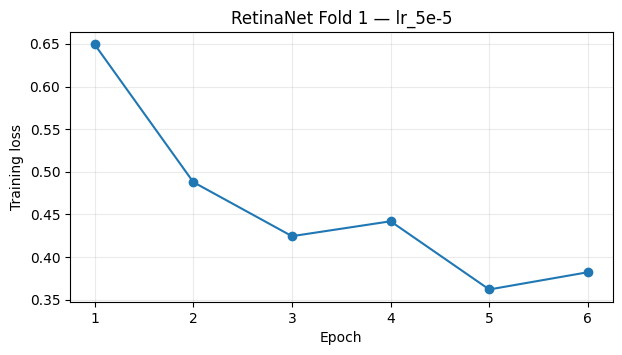

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(train_losses)+1), train_losses, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title(f'RetinaNet Fold {FOLD} — {EXP1_NAME}')
plt.grid(alpha=0.25)
plt.show()


In [ ]:
assert checkpoint_path.is_file()
assert len(train_losses) == EPOCHS
save_validation_predictions(model, OUTPUT_DIR)


Validation inference:   0%|          | 0/4046 [00:00<?, ?it/s]

Saved inference: 438635 predictions to /content/drive/MyDrive/AI_HW2/retinanet_tuning/lr_5e-5/fold_1/predictions_quick.json


In [ ]:
score_saved_predictions(OUTPUT_DIR, EXP1_NAME, EXP1_LR, EXP1_ALPHA)


Evaluation: {
  "mAP": 0.14085718842518244,
  "AP50": 0.270457255483141,
  "AP75": 0.13206035936799973,
  "AP_small": 0.023667525113528726,
  "AP_medium": 0.14368745146866477,
  "AP_large": 0.3202601449369178,
  "inference_ms_per_image": 204.93520655166398,
  "FPS_equivalent_batch1": 4.879591051369209,
  "images_evaluated": 4046,
  "num_predictions": 438635
}
Saved to: /content/drive/MyDrive/AI_HW2/retinanet_tuning/lr_5e-5/fold_1


## Experiment 2 — Focal Loss Modification

**Only change from baseline:** focal-loss `alpha: 0.25 → 0.5` (`gamma=2.0`), **LR remains `1e-4`**. Fresh pretrained model and the same ignored-region masking. Save to a different directory.

In [ ]:
import gc
for name in ['model','optimizer','scaler']:
    if name in globals():
        del globals()[name]
gc.collect()
torch.cuda.empty_cache()

EXP2_NAME = 'focal_alpha_05'
EXP2_LR = 1e-4
EXP2_ALPHA = 0.5

model = create_retinanet(focal_alpha=EXP2_ALPHA)
optimizer, scaler, OUTPUT_DIR, checkpoint_path, start_epoch, train_losses = prepare_run(
    model, EXP2_NAME, EXP2_LR, EXP2_ALPHA
)
assert OUTPUT_DIR == HW_ROOT / 'retinanet_tuning' / EXP2_NAME / 'fold_1'


focal_alpha_05 | fold 1 | resume epoch 0/6


In [ ]:
train_losses = train_run(
    model, optimizer, scaler, checkpoint_path, start_epoch,
    train_losses, EXP2_NAME, EXP2_LR, EXP2_ALPHA
)


focal_alpha_05: epoch 1/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 1: total=0.8862 | classification=0.5779 | bbox=0.3084


focal_alpha_05: epoch 2/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 2: total=0.7655 | classification=0.5048 | bbox=0.2607


focal_alpha_05: epoch 3/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 3: total=0.5571 | classification=0.3180 | bbox=0.2391


... (2 outputs left out)

focal_alpha_05: epoch 5/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 5: total=1.2199 | classification=0.8615 | bbox=0.3584


focal_alpha_05: epoch 6/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 6: total=1.8814 | classification=1.3806 | bbox=0.5008


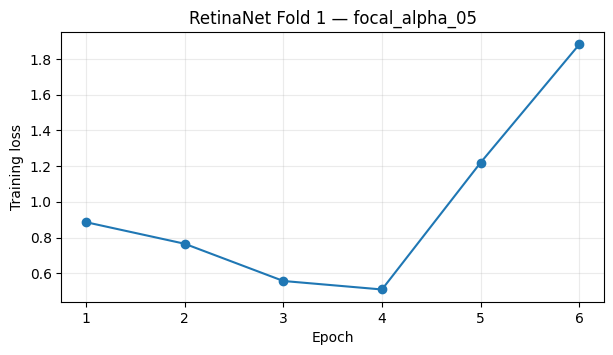

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(train_losses)+1), train_losses, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title(f'RetinaNet Fold {FOLD} — {EXP2_NAME}')
plt.grid(alpha=0.25)
plt.show()


In [ ]:
assert checkpoint_path.is_file()
assert len(train_losses) == EPOCHS
save_validation_predictions(model, OUTPUT_DIR)


Validation inference:   0%|          | 0/4046 [00:00<?, ?it/s]

Saved inference: 1213800 predictions to /content/drive/MyDrive/AI_HW2/retinanet_tuning/focal_alpha_05/fold_1/predictions_quick.json


In [ ]:
score_saved_predictions(OUTPUT_DIR, EXP2_NAME, EXP2_LR, EXP2_ALPHA)


Evaluation: {
  "mAP": 0.010134001888167952,
  "AP50": 0.024803073530043396,
  "AP75": 0.00735831001517176,
  "AP_small": 0.0028963223951018273,
  "AP_medium": 0.011117642214550718,
  "AP_large": 0.017033678439347895,
  "inference_ms_per_image": 203.72939086406473,
  "FPS_equivalent_batch1": 4.908471947806659,
  "images_evaluated": 4046,
  "num_predictions": 1213800
}
Saved to: /content/drive/MyDrive/AI_HW2/retinanet_tuning/focal_alpha_05/fold_1


## Results and file verification


In [ ]:
import pandas as pd
rows = []
for experiment in ('lr_5e-5', 'focal_alpha_05'):
    folder = HW_ROOT / 'retinanet_tuning' / experiment / f'fold_{FOLD}'
    files = {name: (folder / name).is_file() for name in [
        'fold_latest.pth','predictions_quick.json','inference_times.json',
        'metrics_quick.json','config.json'
    ]}
    print(experiment, files)
    if files['metrics_quick.json']:
        metrics = json.loads((folder / 'metrics_quick.json').read_text())
        rows.append(dict(experiment=experiment, **metrics))
if rows:
    display(pd.DataFrame(rows).round(4))


lr_5e-5 {'fold_latest.pth': True, 'predictions_quick.json': True, 'inference_times.json': True, 'metrics_quick.json': True, 'config.json': True}
focal_alpha_05 {'fold_latest.pth': True, 'predictions_quick.json': True, 'inference_times.json': True, 'metrics_quick.json': True, 'config.json': True}


,experiment,mAP,AP50,AP75,AP_small,AP_medium,AP_large,inference_ms_per_image,FPS_equivalent_batch1,images_evaluated,num_predictions
0,lr_5e-5,0.1409,0.2705,0.1321,0.0237,0.1437,0.3203,204.9352,4.8796,4046,438635
1,focal_alpha_05,0.0101,0.0248,0.0074,0.0029,0.0111,0.0170,203.7294,4.9085,4046,1213800


### Notes for preserving baseline outputs

- Original baseline results are **already included above**; leave those cells as they are and do not use Colab **Run all**.
- The baseline checkpoint lives in `AI_HW2/retinanet/fold_1/`, while the two tuning checkpoints live under `AI_HW2/retinanet_tuning/.../fold_1/`.
- A trained model is reinitialized for Experiment 2; it does **not** continue Experiment 1.
- If inference completes but COCO scoring disconnects, rerun the `score_saved_predictions(...)` cell on CPU using the saved JSON; no model retraining is required.
